# 05 — Multi-model fine tuning

## Objective

Tune the remaining ensemble models and the multilayer perceptron, then compare each tuned model with its untuned time-ordered result from notebooks 02–04.

## Leakage-safe design

Within every class, records are ordered by timestamp:

- earliest 60%: parameter-search training period;
- next 20%: validation period used to select one configuration per model;
- final 20%: untouched test period.

After selection, each winning tree model is refit on the complete first 80%. The MLP uses a larger class-aware sample from the first 80% because `MLPClassifier` has no class-weight parameter and full-data training would be dominated by benign traffic. **Macro F1** remains the selection and final comparison metric.

In [1]:
import glob, json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import precision_recall_fscore_support
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

os.environ['LOKY_MAX_CPU_COUNT'] = str(os.cpu_count() or 1)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 220)
sns.set_theme(style='whitegrid')

DATA = '../Data/archive/CICIDS2017_improved'
RESULTS_DIR = 'results'; os.makedirs(RESULTS_DIR, exist_ok=True)
RS = 42
N_JOBS = -1
SEARCH_MIN_PER_CLASS = 2_000
SEARCH_MAX_PER_CLASS = 20_000
MLP_FINAL_MIN_PER_CLASS = 5_000
MLP_FINAL_MAX_PER_CLASS = 50_000

/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-j_yse5jb because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


## 1. Load and clean

The cleaning and feature exclusions match the preceding modeling notebooks so final test scores remain comparable.

In [2]:
files = sorted(glob.glob(f'{DATA}/*.csv'))
if not files:
    raise FileNotFoundError(f'No CSV files found under {DATA}')

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df['y'] = df['Label'].where(~df['Label'].str.endswith(' - Attempted'), 'BENIGN')
df['ts'] = pd.to_datetime(df['Timestamp'])

drop = ['id', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port',
        'Timestamp', 'Attempted Category', 'Label']
X = df.drop(columns=drop + ['y', 'ts']).replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.max())
constant = [c for c in X if X[c].nunique() <= 1]
X = X.drop(columns=constant)
FEATURES = list(X.columns)

data = X.assign(y=df['y'].values, ts=df['ts'].values)
before = len(data)
data = data.drop_duplicates(subset=FEATURES + ['y']).reset_index(drop=True)

print(f'Files: {len(files)} | features: {len(FEATURES)}')
print(f'Duplicates removed: {before - len(data):,} | rows retained: {len(data):,}')
display(data['y'].value_counts().rename('flows').to_frame())
del df, X

Files: 5 | features: 83
Duplicates removed: 258,629 | rows retained: 1,841,347


,flows
y,
BENIGN,1434950
DoS Hulk,158468
DDoS,95144
Portscan,90620
Infiltration - Portscan,41179
DoS GoldenEye,7567
FTP-Patator,3972
DoS Slowloris,3859
SSH-Patator,2961


## 2. Temporal split and class-aware samples

In [3]:
LABELS = sorted(data['y'].unique(), key=lambda c: (c != 'BENIGN', c))
encoder = LabelEncoder().fit(LABELS)
yall = encoder.transform(data['y'])

rank = data.groupby('y')['ts'].rank(method='first', pct=True)
search_train_idx = data.index[rank <= 0.60].to_numpy()
validation_idx = data.index[(rank > 0.60) & (rank <= 0.80)].to_numpy()
final_train_idx = data.index[rank <= 0.80].to_numpy()
test_idx = data.index[rank > 0.80].to_numpy()

Xall = data[FEATURES].astype('float32').to_numpy()
del data

def class_aware_sample(indices, minimum, maximum, seed=RS):
    rng = np.random.default_rng(seed)
    selected, rows = [], []
    for class_id, class_name in enumerate(encoder.classes_):
        available = indices[yall[indices] == class_id]
        target = min(maximum, max(minimum, len(available)))
        chosen = rng.choice(available, size=target, replace=len(available) < target)
        selected.append(chosen)
        rows.append({'class': class_name, 'available': len(available),
                     'selected': target, 'replacement': len(available) < target})
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return selected, pd.DataFrame(rows)

search_idx, search_sampling = class_aware_sample(
    search_train_idx, SEARCH_MIN_PER_CLASS, SEARCH_MAX_PER_CLASS
)
mlp_final_idx, mlp_final_sampling = class_aware_sample(
    final_train_idx, MLP_FINAL_MIN_PER_CLASS, MLP_FINAL_MAX_PER_CLASS, RS + 1
)

print(f'Search train period: {len(search_train_idx):,} | search sample: {len(search_idx):,}')
print(f'Validation: {len(validation_idx):,} | final train: {len(final_train_idx):,} | test: {len(test_idx):,}')
print(f'MLP final refit sample: {len(mlp_final_idx):,}')
display(search_sampling)

Search train period: 1,104,801 | search sample: 125,238
Validation: 368,270 | final train: 1,473,071 | test: 368,276
MLP final refit sample: 288,996


,class,available,selected,replacement
0,BENIGN,860970,20000,False
1,Botnet,441,2000,True
2,DDoS,57086,20000,False
3,DoS GoldenEye,4540,4540,False
4,DoS Hulk,95080,20000,False
5,DoS Slowhttptest,1044,2000,True
6,DoS Slowloris,2315,2315,False
7,FTP-Patator,2383,2383,False
8,Heartbleed,6,2000,True
9,Infiltration,21,2000,True


## 3. Candidate configurations

Candidate 1 reproduces each notebook’s original configuration. The remaining candidates vary model capacity, learning rate, regularization, or sampling. The search is intentionally compact because the goal is a defensible capstone comparison rather than exhaustive optimization.

In [4]:
GRIDS = {
    'RandomForest': [
        {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': None},
        {'n_estimators': 250, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'},
        {'n_estimators': 250, 'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'},
        {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 0.5, 'class_weight': 'balanced_subsample'},
    ],
    'ExtraTrees': [
        {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': None},
        {'n_estimators': 250, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced'},
        {'n_estimators': 250, 'max_depth': 35, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'class_weight': 'balanced'},
        {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 0.5, 'class_weight': 'balanced'},
    ],
    'XGBoost': [
        {'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.10, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 1, 'reg_lambda': 1.0},
        {'n_estimators': 350, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'min_child_weight': 1, 'reg_lambda': 1.0},
        {'n_estimators': 300, 'max_depth': 10, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_child_weight': 2, 'reg_lambda': 2.0},
        {'n_estimators': 250, 'max_depth': 6, 'learning_rate': 0.08, 'subsample': 1.0, 'colsample_bytree': 0.8, 'min_child_weight': 5, 'reg_lambda': 5.0},
    ],
    'LightGBM': [
        {'n_estimators': 200, 'learning_rate': 0.10, 'num_leaves': 63, 'max_depth': -1, 'min_child_samples': 20, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 0.0},
        {'n_estimators': 400, 'learning_rate': 0.05, 'num_leaves': 63, 'max_depth': -1, 'min_child_samples': 20, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 1.0},
        {'n_estimators': 350, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'min_child_samples': 30, 'subsample': 0.9, 'colsample_bytree': 1.0, 'reg_lambda': 1.0},
        {'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 127, 'max_depth': -1, 'min_child_samples': 50, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 2.0},
    ],
    'MLP': [
        {'hidden_layer_sizes': (128, 64), 'alpha': 1e-4, 'learning_rate_init': 1e-3, 'batch_size': 2048},
        {'hidden_layer_sizes': (256, 128), 'alpha': 1e-4, 'learning_rate_init': 1e-3, 'batch_size': 2048},
        {'hidden_layer_sizes': (128, 64, 32), 'alpha': 1e-4, 'learning_rate_init': 5e-4, 'batch_size': 2048},
        {'hidden_layer_sizes': (128, 64), 'alpha': 1e-3, 'learning_rate_init': 5e-4, 'batch_size': 1024},
        {'hidden_layer_sizes': (256, 128, 64), 'alpha': 1e-3, 'learning_rate_init': 5e-4, 'batch_size': 2048},
    ],
}

pd.DataFrame([{'model': model, 'candidate': i, **params}
              for model, candidates in GRIDS.items()
              for i, params in enumerate(candidates, 1)])

,model,candidate,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,num_leaves,min_child_samples,hidden_layer_sizes,alpha,learning_rate_init,batch_size
0,RandomForest,1,100.0,NaN,1.0,sqrt,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RandomForest,2,250.0,NaN,1.0,sqrt,balanced_subsample,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RandomForest,3,250.0,30.0,2.0,sqrt,balanced_subsample,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RandomForest,4,200.0,NaN,2.0,0.5,balanced_subsample,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ExtraTrees,1,100.0,NaN,1.0,sqrt,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ExtraTrees,2,250.0,NaN,1.0,sqrt,balanced,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ExtraTrees,3,250.0,35.0,2.0,sqrt,balanced,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ExtraTrees,4,200.0,NaN,2.0,0.5,balanced,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,XGBoost,1,200.0,8.0,NaN,NaN,NaN,0.10,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
9,XGBoost,2,350.0,6.0,NaN,NaN,NaN,0.05,0.9,0.9,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Parameter search

Every candidate is ranked by validation macro F1. The untouched final test period is not read during selection.

In [5]:
def make_model(model_name, params):
    if model_name == 'RandomForest':
        return RandomForestClassifier(**params, n_jobs=N_JOBS, random_state=RS)
    if model_name == 'ExtraTrees':
        return ExtraTreesClassifier(**params, n_jobs=N_JOBS, random_state=RS)
    if model_name == 'XGBoost':
        return XGBClassifier(**params, tree_method='hist', n_jobs=N_JOBS,
                             random_state=RS, eval_metric='mlogloss')
    if model_name == 'LightGBM':
        return LGBMClassifier(**params, n_jobs=N_JOBS, class_weight='balanced',
                              random_state=RS, verbose=-1)
    raise KeyError(model_name)

def metrics_for(y_true, predicted):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, predicted, labels=encoder.transform(LABELS), zero_division=0
    )
    return {
        'macro_precision': precision.mean(), 'macro_recall': recall.mean(),
        'macro_f1': f1.mean(), 'weighted_f1': np.average(f1, weights=support),
        'attack_macro_f1': f1[1:].mean(),
    }

search_rows = []
best_params = {}

for model_name in ['RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM']:
    for candidate, params in enumerate(GRIDS[model_name], 1):
        model = make_model(model_name, params)
        started = time.perf_counter()
        model.fit(Xall[search_idx], yall[search_idx])
        fit_seconds = time.perf_counter() - started
        started = time.perf_counter()
        predicted = model.predict(Xall[validation_idx])
        predict_seconds = time.perf_counter() - started
        row = {'model': model_name, 'candidate': candidate, **metrics_for(yall[validation_idx], predicted),
               'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds,
               'parameters': json.dumps(params, default=str)}
        search_rows.append(row)
        print(f'{model_name:13s} candidate {candidate} | validation macro F1 {row["macro_f1"]:.4f} | fit {fit_seconds:.1f}s')

# Scale once for every MLP candidate.
def signed_log(array):
    return np.sign(array) * np.log1p(np.abs(array))

search_scaler = StandardScaler()
X_mlp_search = search_scaler.fit_transform(signed_log(Xall[search_idx])).astype('float32')
X_mlp_validation = search_scaler.transform(signed_log(Xall[validation_idx])).astype('float32')

for candidate, params in enumerate(GRIDS['MLP'], 1):
    model = MLPClassifier(**params, activation='relu', solver='adam', max_iter=60,
                          early_stopping=True, validation_fraction=0.1,
                          n_iter_no_change=6, random_state=RS)
    started = time.perf_counter()
    model.fit(X_mlp_search, yall[search_idx])
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    predicted = model.predict(X_mlp_validation)
    predict_seconds = time.perf_counter() - started
    row = {'model': 'MLP', 'candidate': candidate, **metrics_for(yall[validation_idx], predicted),
           'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds,
           'iterations': model.n_iter_, 'parameters': json.dumps(params, default=str)}
    search_rows.append(row)
    print(f'MLP           candidate {candidate} | validation macro F1 {row["macro_f1"]:.4f} | fit {fit_seconds:.1f}s')

del X_mlp_search, X_mlp_validation
search_results = pd.DataFrame(search_rows).sort_values(['model', 'macro_f1'], ascending=[True, False])
search_results.to_csv(f'{RESULTS_DIR}/05_tuning_search_results.csv', index=False)

for model_name in GRIDS:
    winning = search_results[search_results['model'] == model_name].iloc[0]
    best_params[model_name] = GRIDS[model_name][int(winning['candidate']) - 1]

display(search_results.round(4))

RandomForest  candidate 1 | validation macro F1 0.9251 | fit 1.6s


RandomForest  candidate 2 | validation macro F1 0.8855 | fit 5.9s


RandomForest  candidate 3 | validation macro F1 0.8826 | fit 6.0s


RandomForest  candidate 4 | validation macro F1 0.9132 | fit 19.6s


ExtraTrees    candidate 1 | validation macro F1 0.8910 | fit 0.9s


...

MLP           candidate 2 | validation macro F1 0.8686 | fit 11.3s


MLP           candidate 3 | validation macro F1 0.7550 | fit 10.0s


MLP           candidate 4 | validation macro F1 0.8358 | fit 14.5s


MLP           candidate 5 | validation macro F1 0.8226 | fit 27.6s


,model,candidate,macro_precision,macro_recall,macro_f1,weighted_f1,attack_macro_f1,fit_seconds,predict_seconds,parameters,iterations
4,ExtraTrees,1,0.9192,0.9169,0.8910,0.9934,0.8839,0.8797,0.3840,"{""n_estimators"": 100, ""max_depth"": null, ""min_...",NaN
5,ExtraTrees,2,0.9189,0.9169,0.8909,0.9934,0.8838,2.4833,0.8158,"{""n_estimators"": 250, ""max_depth"": null, ""min_...",NaN
7,ExtraTrees,4,0.8735,0.9264,0.8607,0.9928,0.8516,5.1282,0.6200,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",NaN
6,ExtraTrees,3,0.8510,0.8689,0.8331,0.9923,0.8222,2.2051,0.7450,"{""n_estimators"": 250, ""max_depth"": 35, ""min_sa...",NaN
12,LightGBM,1,0.8603,0.9922,0.8906,0.9939,0.8835,13.3354,4.3087,"{""n_estimators"": 200, ""learning_rate"": 0.1, ""n...",NaN
13,LightGBM,2,0.8599,0.9927,0.8894,0.9937,0.8822,16.8045,6.3195,"{""n_estimators"": 400, ""learning_rate"": 0.05, ""...",NaN
14,LightGBM,3,0.8466,0.9925,0.8805,0.9937,0.8728,12.6007,4.7867,"{""n_estimators"": 350, ""learning_rate"": 0.05, ""...",NaN
15,LightGBM,4,0.8418,0.9926,0.8771,0.9937,0.8691,13.4555,4.6519,"{""n_estimators"": 300, ""learning_rate"": 0.05, ""...",NaN
17,MLP,2,0.8488,0.9911,0.8686,0.9923,0.8601,11.2675,0.3814,"{""hidden_layer_sizes"": [256, 128], ""alpha"": 0....",23.0
16,MLP,1,0.8348,0.9609,0.8369,0.9926,0.8262,11.0605,0.2105,"{""hidden_layer_sizes"": [128, 64], ""alpha"": 0.0...",36.0


## 5. Validation results

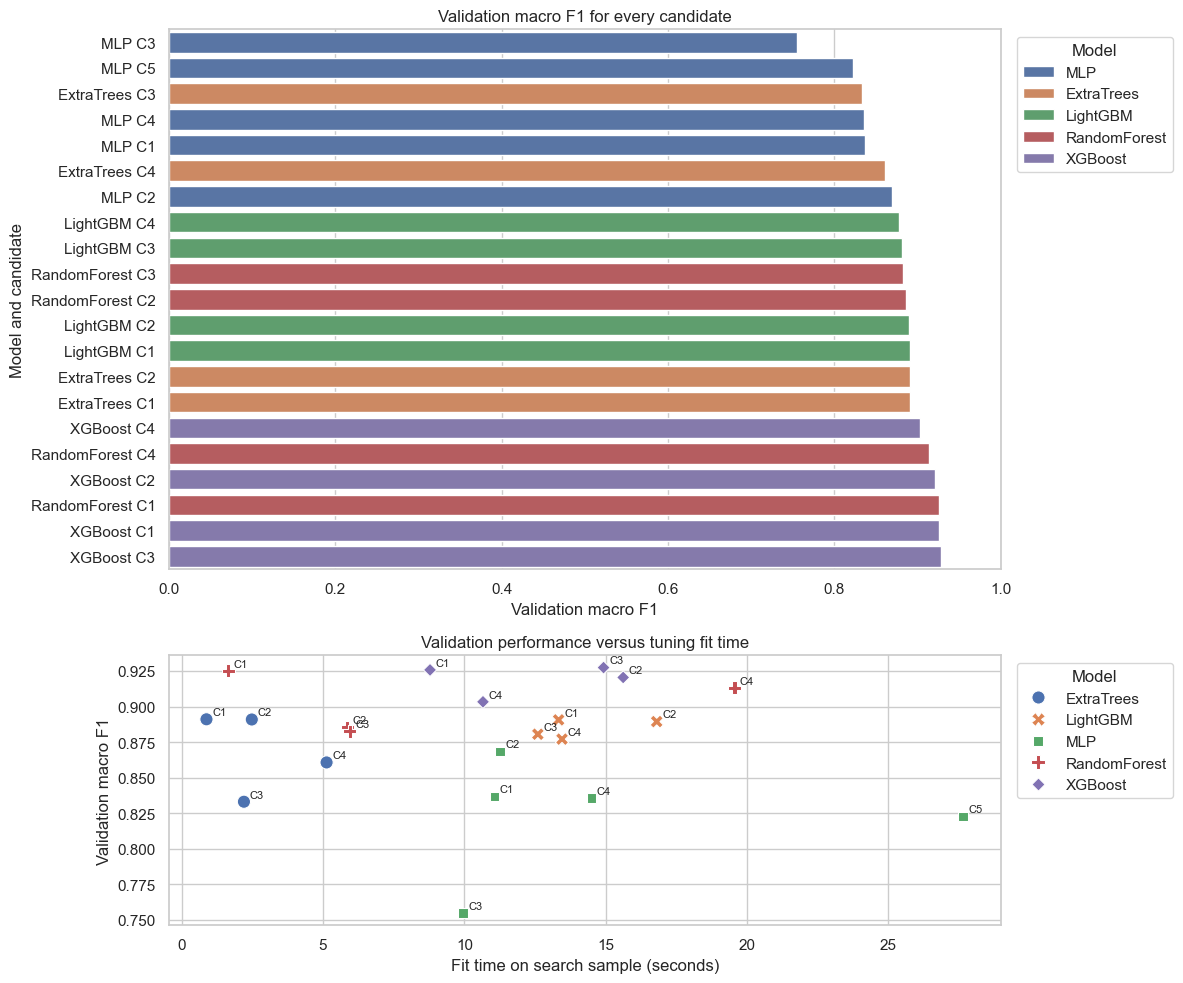

,model,candidate,macro_f1,weighted_f1,fit_seconds,parameters
0,ExtraTrees,1,0.8910,0.9934,0.8797,"{""n_estimators"": 100, ""max_depth"": null, ""min_..."
1,LightGBM,1,0.8906,0.9939,13.3354,"{""n_estimators"": 200, ""learning_rate"": 0.1, ""n..."
2,MLP,2,0.8686,0.9923,11.2675,"{""hidden_layer_sizes"": [256, 128], ""alpha"": 0...."
3,RandomForest,1,0.9251,0.9932,1.6498,"{""n_estimators"": 100, ""max_depth"": null, ""min_..."
4,XGBoost,3,0.9274,0.9938,14.9245,"{""n_estimators"": 300, ""max_depth"": 10, ""learni..."


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [2, 1]})
plot_search = search_results.copy()
plot_search['configuration'] = plot_search['model'] + ' C' + plot_search['candidate'].astype(str)
sns.barplot(data=plot_search.sort_values('macro_f1'), y='configuration', x='macro_f1',
            hue='model', dodge=False, ax=axes[0])
axes[0].set_xlim(0, 1)
axes[0].set_title('Validation macro F1 for every candidate')
axes[0].set_xlabel('Validation macro F1')
axes[0].set_ylabel('Model and candidate')
axes[0].legend(title='Model', bbox_to_anchor=(1.01, 1), loc='upper left')

sns.scatterplot(data=plot_search, x='fit_seconds', y='macro_f1', hue='model',
                style='model', s=90, ax=axes[1])
for _, row in plot_search.iterrows():
    axes[1].annotate(f'C{int(row.candidate)}', (row.fit_seconds, row.macro_f1),
                     xytext=(4, 3), textcoords='offset points', fontsize=8)
axes[1].set_title('Validation performance versus tuning fit time')
axes[1].set_xlabel('Fit time on search sample (seconds)')
axes[1].set_ylabel('Validation macro F1')
axes[1].legend(title='Model', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

winners = search_results.groupby('model', as_index=False).first()
display(winners[['model', 'candidate', 'macro_f1', 'weighted_f1', 'fit_seconds', 'parameters']].round(4))

## 6. Refit the winners and evaluate once

The four tree ensembles use all rows from the first 80% of each class. The MLP uses the documented class-aware final-training sample.

In [7]:
final_rows = []
per_class_rows = []
test_predictions = {}

for model_name in ['RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM']:
    model = make_model(model_name, best_params[model_name])
    started = time.perf_counter()
    model.fit(Xall[final_train_idx], yall[final_train_idx])
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    predicted = model.predict(Xall[test_idx])
    predict_seconds = time.perf_counter() - started
    score = metrics_for(yall[test_idx], predicted)
    winner = winners[winners['model'] == model_name].iloc[0]
    final_rows.append({'model': model_name, 'selected_candidate': int(winner.candidate),
                       **score, 'training_rows': len(final_train_idx),
                       'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds,
                       'parameters': json.dumps(best_params[model_name], default=str)})
    pr, rc, f1, support = precision_recall_fscore_support(
        yall[test_idx], predicted, labels=encoder.transform(LABELS), zero_division=0)
    per_class_rows.append(pd.DataFrame({'model': model_name, 'class': LABELS,
        'precision': pr, 'recall': rc, 'f1': f1, 'support': support}))
    test_predictions[model_name] = predicted
    print(f'{model_name:13s} test macro F1 {score["macro_f1"]:.4f} | fit {fit_seconds:.1f}s')

# Final MLP refit with scaling learned only from its final-training sample.
mlp_scaler = StandardScaler()
X_mlp_train = mlp_scaler.fit_transform(signed_log(Xall[mlp_final_idx])).astype('float32')
X_mlp_test = mlp_scaler.transform(signed_log(Xall[test_idx])).astype('float32')
mlp = MLPClassifier(**best_params['MLP'], activation='relu', solver='adam', max_iter=60,
                    early_stopping=True, validation_fraction=0.1,
                    n_iter_no_change=6, random_state=RS)
started = time.perf_counter()
mlp.fit(X_mlp_train, yall[mlp_final_idx])
fit_seconds = time.perf_counter() - started
started = time.perf_counter()
predicted = mlp.predict(X_mlp_test)
predict_seconds = time.perf_counter() - started
score = metrics_for(yall[test_idx], predicted)
winner = winners[winners['model'] == 'MLP'].iloc[0]
final_rows.append({'model': 'MLP', 'selected_candidate': int(winner.candidate), **score,
                   'training_rows': len(mlp_final_idx), 'fit_seconds': fit_seconds,
                   'predict_seconds': predict_seconds, 'iterations': mlp.n_iter_,
                   'parameters': json.dumps(best_params['MLP'], default=str)})
pr, rc, f1, support = precision_recall_fscore_support(
    yall[test_idx], predicted, labels=encoder.transform(LABELS), zero_division=0)
per_class_rows.append(pd.DataFrame({'model': 'MLP', 'class': LABELS,
    'precision': pr, 'recall': rc, 'f1': f1, 'support': support}))
test_predictions['MLP'] = predicted
print(f'MLP           test macro F1 {score["macro_f1"]:.4f} | fit {fit_seconds:.1f}s')

final_results = pd.DataFrame(final_rows).sort_values('macro_f1', ascending=False)
per_class_results = pd.concat(per_class_rows, ignore_index=True)
final_results.to_csv(f'{RESULTS_DIR}/05_tuned_model_summary.csv', index=False)
per_class_results.to_csv(f'{RESULTS_DIR}/05_tuned_per_class_metrics.csv', index=False)
display(final_results.round(4))

RandomForest  test macro F1 0.8908 | fit 69.2s


ExtraTrees    test macro F1 0.8924 | fit 19.5s


XGBoost       test macro F1 0.9053 | fit 105.6s


LightGBM      test macro F1 0.9182 | fit 64.7s


MLP           test macro F1 0.8075 | fit 38.5s


,model,selected_candidate,macro_precision,macro_recall,macro_f1,weighted_f1,attack_macro_f1,training_rows,fit_seconds,predict_seconds,parameters,iterations
3,LightGBM,1,0.9340,0.9086,0.9182,0.9894,0.9129,1473071,64.6582,5.2291,"{""n_estimators"": 200, ""learning_rate"": 0.1, ""n...",NaN
2,XGBoost,3,0.9813,0.8627,0.9053,0.9909,0.8992,1473071,105.6253,1.0047,"{""n_estimators"": 300, ""max_depth"": 10, ""learni...",NaN
1,ExtraTrees,1,0.9753,0.8464,0.8924,0.9900,0.8853,1473071,19.4781,0.3622,"{""n_estimators"": 100, ""max_depth"": null, ""min_...",NaN
0,RandomForest,1,0.9725,0.8501,0.8908,0.9881,0.8836,1473071,69.1767,0.3734,"{""n_estimators"": 100, ""max_depth"": null, ""min_...",NaN
4,MLP,2,0.7869,0.9315,0.8075,0.9905,0.7948,288996,38.4552,0.4163,"{""hidden_layer_sizes"": [256, 128], ""alpha"": 0....",29.0


## 7. Tuned versus untuned results

HistGradientBoosting tuning from notebook 04 is included so this table covers every previously tested non-linear model.

,model,macro_f1_base,weighted_f1_base,attack_macro_f1_base,macro_f1_tuned,weighted_f1_tuned,attack_macro_f1_tuned,macro_f1_change,preferred_version
1,HistGradientBoosting,0.9236,0.9907,0.9186,0.9199,0.9904,0.9147,-0.0037,base
2,LightGBM,0.9182,0.9894,0.9129,0.9182,0.9894,0.9129,-0.0000,base
4,XGBoost,0.9108,0.9910,0.9051,0.9053,0.9909,0.8992,-0.0055,base
0,ExtraTrees,0.8924,0.9900,0.8853,0.8924,0.9900,0.8853,0.0000,base
3,RandomForest,0.8908,0.9881,0.8836,0.8908,0.9881,0.8836,0.0000,base
5,MLP,0.7312,0.9880,0.7136,0.8075,0.9905,0.7948,0.0763,tuned


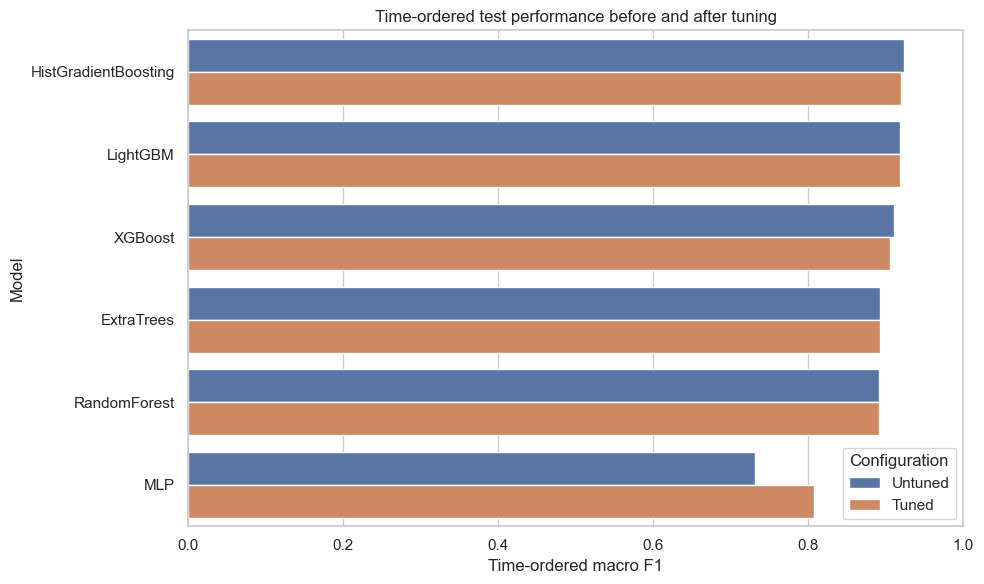

In [8]:
base = pd.read_csv(f'{RESULTS_DIR}/02_summary.csv')
base = base[base['split'] == 'time-ordered'][['model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']]
base_mlp = pd.read_csv(f'{RESULTS_DIR}/03_mlp_summary.csv')
base_mlp = base_mlp[base_mlp['split'] == 'time-ordered'][['model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']]
base_mlp['model'] = 'MLP'
base = pd.concat([base, base_mlp], ignore_index=True)
base['model'] = base['model'].replace({'HistGB': 'HistGradientBoosting'})

tuned = final_results[['model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']].copy()
tuned_hist = pd.read_csv(f'{RESULTS_DIR}/04_tuned_summary.csv')[['model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']]
tuned_hist['model'] = 'HistGradientBoosting'
tuned = pd.concat([tuned, tuned_hist], ignore_index=True)

comparison = base.merge(tuned, on='model', suffixes=('_base', '_tuned'))
comparison['macro_f1_change'] = comparison['macro_f1_tuned'] - comparison['macro_f1_base']
comparison['preferred_version'] = np.where(comparison['macro_f1_change'] > 0, 'tuned', 'base')
comparison = comparison.sort_values('macro_f1_tuned', ascending=False)
comparison.to_csv(f'{RESULTS_DIR}/05_base_vs_tuned_comparison.csv', index=False)
display(comparison.round(4))

plot_compare = comparison.melt(id_vars='model', value_vars=['macro_f1_base', 'macro_f1_tuned'],
                               var_name='version', value_name='macro_f1')
plot_compare['version'] = plot_compare['version'].map(
    {'macro_f1_base': 'Untuned', 'macro_f1_tuned': 'Tuned'})
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_compare, y='model', x='macro_f1', hue='version', ax=ax)
ax.set_xlim(0, 1)
ax.set_xlabel('Time-ordered macro F1')
ax.set_ylabel('Model')
ax.set_title('Time-ordered test performance before and after tuning')
ax.legend(title='Configuration')
plt.tight_layout(); plt.show()

## 8. Where tuning helped or hurt

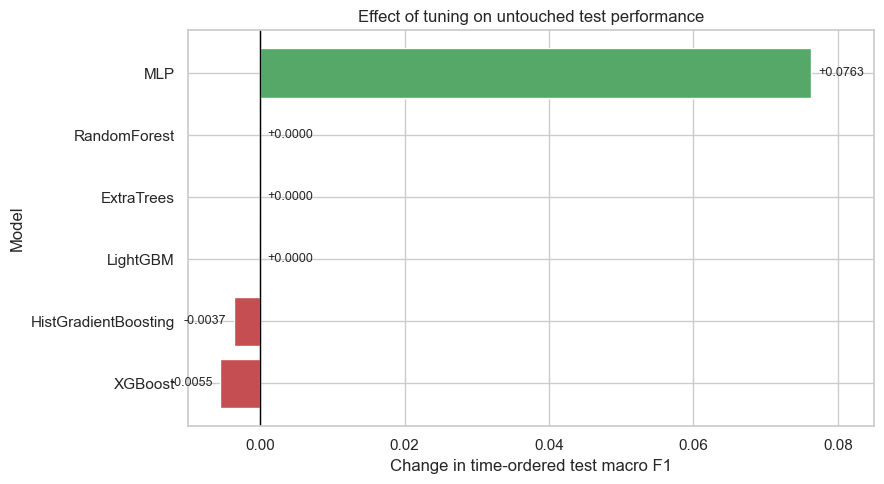

Highest tuned score: HistGradientBoosting (0.9199)
Largest tuning change: MLP (+0.0763)
Models improved on the untouched test: 1 of 6


In [9]:
comparison['macro_f1_change'] = comparison['macro_f1_change'].mask(
    comparison['macro_f1_change'].abs() < 1e-10, 0.0
)
ordered = comparison.sort_values('macro_f1_change')
colors = np.where(ordered['macro_f1_change'] >= 0, '#55A868', '#C44E52')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ordered['model'], ordered['macro_f1_change'], color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlim(-0.010, 0.085)
ax.set_xlabel('Change in time-ordered test macro F1')
ax.set_ylabel('Model')
ax.set_title('Effect of tuning on untouched test performance')
for y, value in enumerate(ordered['macro_f1_change']):
    ax.text(value + (0.001 if value >= 0 else -0.001), y, f'{value:+.4f}',
            va='center', ha='left' if value >= 0 else 'right', fontsize=9)
plt.tight_layout(); plt.show()

best_row = comparison.loc[comparison['macro_f1_tuned'].idxmax()]
largest_gain = comparison.loc[comparison['macro_f1_change'].idxmax()]
print(f'Highest tuned score: {best_row.model} ({best_row.macro_f1_tuned:.4f})')
print(f'Largest tuning change: {largest_gain.model} ({largest_gain.macro_f1_change:+.4f})')
print(f'Models improved on the untouched test: {(comparison.macro_f1_change > 0).sum()} of {len(comparison)}')


## 9. Interpretation

Only the MLP improved materially on the untouched time-ordered test period. Candidate 2, with hidden layers `(256, 128)`, increased MLP macro F1 from **0.7312 to 0.8075** (**+0.0763**). Despite that gain, it remained **0.1161 below** the original HistGradientBoosting model.

LightGBM, Random Forest, and Extra Trees selected candidate 1, which reproduces their original settings, so their final scores were unchanged. The selected XGBoost candidate scored **0.9053**, down **0.0055**, and tuned HistGradientBoosting scored **0.9199**, down **0.0037**.

The recommended model remains the original HistGradientBoosting configuration with **0.9236 time-ordered macro F1**. These results reinforce that validation improvement does not guarantee better performance in a later traffic period.
